# Simple ISIS accelerator test

### Imports

In [1]:
import sys
from pathlib import Path
import numpy as np 
import matplotlib.pyplot as plt
import xobjects as xo
from sim_utils import build_line, add_monitor, add_spacecharge_xfields

sys.path.append(str((Path.cwd().parent / "indirect_space_charge_python").resolve()))
from config_tools import install_spacecharge_frozen

### Parameters for the simulation

In [2]:
n_monitors = 5
n_turns = 50
n_spacecharge_elements = 20

# No SC

In [3]:
line = build_line()

particles = line.build_particles(x=0, y=0, px=0, py=0)

length = line.get_length()
for i, s in enumerate(np.linspace(0, length, n_monitors, endpoint=False)):
    line = add_monitor(line, particles, s, n_turns, name=i+1)

line.build_tracker(_context=xo.ContextCpu(omp_num_threads=10))
line.track(particles, num_turns=n_turns, time=True)

x = np.array([line.element_dict[f'monitor_{i+1}'].x.T for i in range(n_monitors)])
x_nosc = x.T.reshape(-1, np.shape(x)[2])

/home/robert/projects/indirect_space_charge_python/Lattice_Files/02_Aperture_Lattice/ISIS.injected_beam


Slicing line: 100%|██████████| 3984/3984 [00:00<00:00, 389068.60it/s]


Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.


# Xsuite

In [4]:
line = build_line()

particles = line.build_particles(x=0, y=0, px=0, py=0)

length = line.get_length()
for i, s in enumerate(np.linspace(0, length, n_monitors, endpoint=False)):
    line = add_monitor(line, particles, s, n_turns, name=i+1)

line = add_spacecharge_xfields(line, 1e12, n_spacecharge_elements, nemitt_x=1e-6, nemitt_y=1e-6)
line.build_tracker(_context=xo.ContextCpu(omp_num_threads=10))
line.track(particles, num_turns=n_turns, time=True)

x = np.array([line.element_dict[f'monitor_{i+1}'].x.T for i in range(n_monitors)])
x_xsuite = x.T.reshape(-1, np.shape(x)[2])

/home/robert/projects/indirect_space_charge_python/Lattice_Files/02_Aperture_Lattice/ISIS.injected_beam


Slicing line: 100%|██████████| 3985/3985 [00:00<00:00, 274171.24it/s]


Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.


# My code

In [5]:
line = build_line()

particles = line.build_particles(x=0, y=0, px=0, py=0)

length = line.get_length()
for i, s in enumerate(np.linspace(0, length, n_monitors, endpoint=False)):
    line = add_monitor(line, particles, s, n_turns, name=i+1)

line = install_spacecharge_frozen(line, 1e12, n_spacecharge_elements, nemitt_x=1e-6, nemitt_y=1e-6, indirect_sc=False)

line.build_tracker(_context=xo.ContextCpu(omp_num_threads=10))
line.track(particles, num_turns=n_turns, time=True)

x = np.array([line.element_dict[f'monitor_{i+1}'].x.T for i in range(n_monitors)])
x_mycode = x.T.reshape(-1, np.shape(x)[2])

/home/robert/projects/indirect_space_charge_python/Lattice_Files/02_Aperture_Lattice/ISIS.injected_beam


Slicing line: 100%|██████████| 3985/3985 [00:00<00:00, 303405.42it/s]


Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.


# Plots

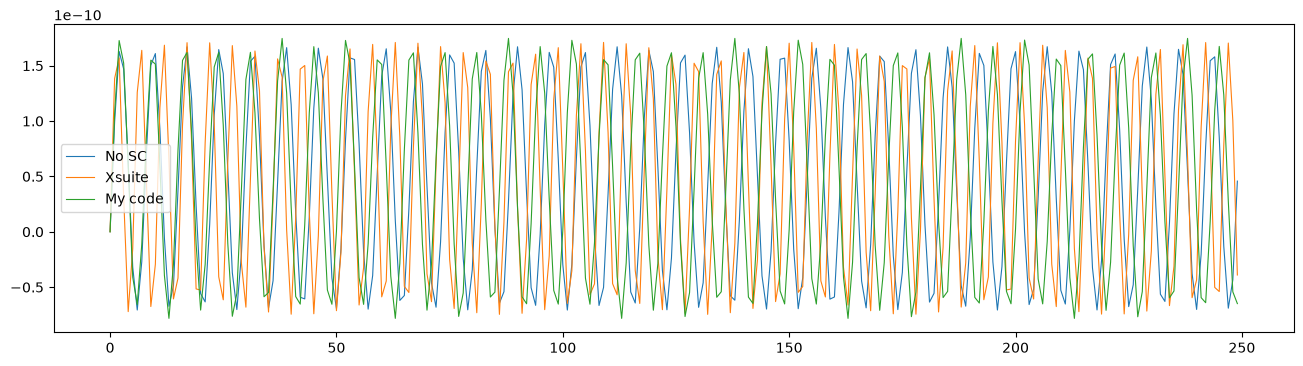

In [6]:
fig, ax = plt.subplots(1, figsize=(16,4))
lw=0.8
ax.plot(x_nosc, lw=lw, label='No SC')
ax.plot(x_xsuite, lw=lw, label='Xsuite')
ax.plot(x_mycode, lw=lw, label='My code')
ax.legend()
plt.show()

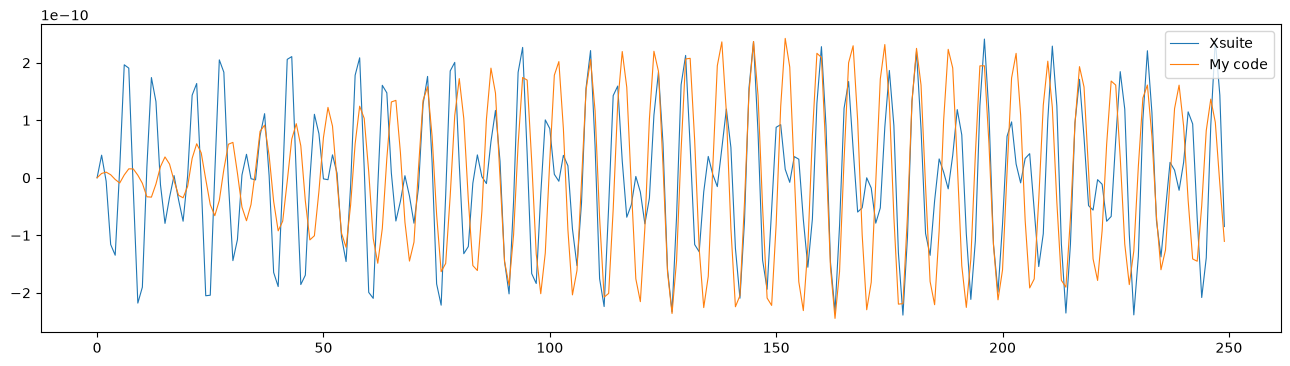

In [7]:
fig, ax = plt.subplots(1, figsize=(16,4))
lw=0.8
ax.plot(x_xsuite-x_nosc, lw=lw, label='Xsuite')
ax.plot(x_mycode-x_nosc, lw=lw, label='My code')
ax.legend()
plt.show()

In [8]:
print((x_xsuite-x_nosc).T)

[[ 0.00000000e+00  3.93350767e-11 -5.87203487e-12 -1.15989310e-10
  -1.34628303e-10  1.65455065e-11  1.96515556e-10  1.90730969e-10
  -2.08641969e-11 -2.17912513e-10 -1.90235507e-10  1.87447664e-11
   1.74322357e-10  1.32545464e-10 -1.20911897e-11 -7.92897392e-11
  -3.42788813e-11  3.84435408e-12 -3.84466885e-11 -7.55190156e-11
   3.18146689e-12  1.43650915e-10  1.63968823e-10 -7.24340790e-12
  -2.05147367e-10 -2.04213356e-10  8.08763036e-12  2.05070065e-10
   1.83579804e-10 -6.73642546e-12 -1.44052162e-10 -1.07563474e-10
   4.80279364e-12  4.08562537e-11 -1.61710674e-12 -3.64723427e-12
   7.33973162e-11  1.11517141e-10  3.73705487e-12 -1.64622922e-10
  -1.89116280e-10 -4.46878055e-12  2.05951766e-10  2.10752960e-10
   4.52287253e-12 -1.85650383e-10 -1.69341693e-10 -2.58628671e-12
   1.10448422e-10  7.66783328e-11 -1.86822723e-12 -3.32653963e-12
   3.99148487e-11  8.09337566e-12 -1.03509305e-10 -1.45654318e-10
  -1.41172047e-11  1.78321535e-10  2.08682998e-10  1.73659649e-11
  -1.99277